In [ ]:
%matplotlib ipympl

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import cm
import make_HPO_pes as mpes

In [2]:
HPO_PES_file = 'HPO_PES_f12b.txt'
print(mpes.get_non_linear_p(HPO_PES_file))

[1.48332858e+00 1.45449985e+00 1.04379542e+02 1.50379294e+00
 1.68800000e+00 1.50000000e+01 1.00000000e+01 0.00000000e+00
 0.00000000e+00 6.06098395e-03]


In [3]:
p, orders = mpes.get_coeffs_orders(HPO_PES_file)
nonlin_p = mpes.get_non_linear_p(HPO_PES_file)
pes = mpes.get_pes(p, nonlin_p.copy(), orders)

C:\Users\ryanm\AppData\Local\Temp\ipykernel_36176\554406826.py:34: UserWarning: The following kwargs were not used by contour: 'label'
  contour = ax[i].contourf(
C:\Users\ryanm\AppData\Local\Temp\ipykernel_36176\554406826.py:41: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


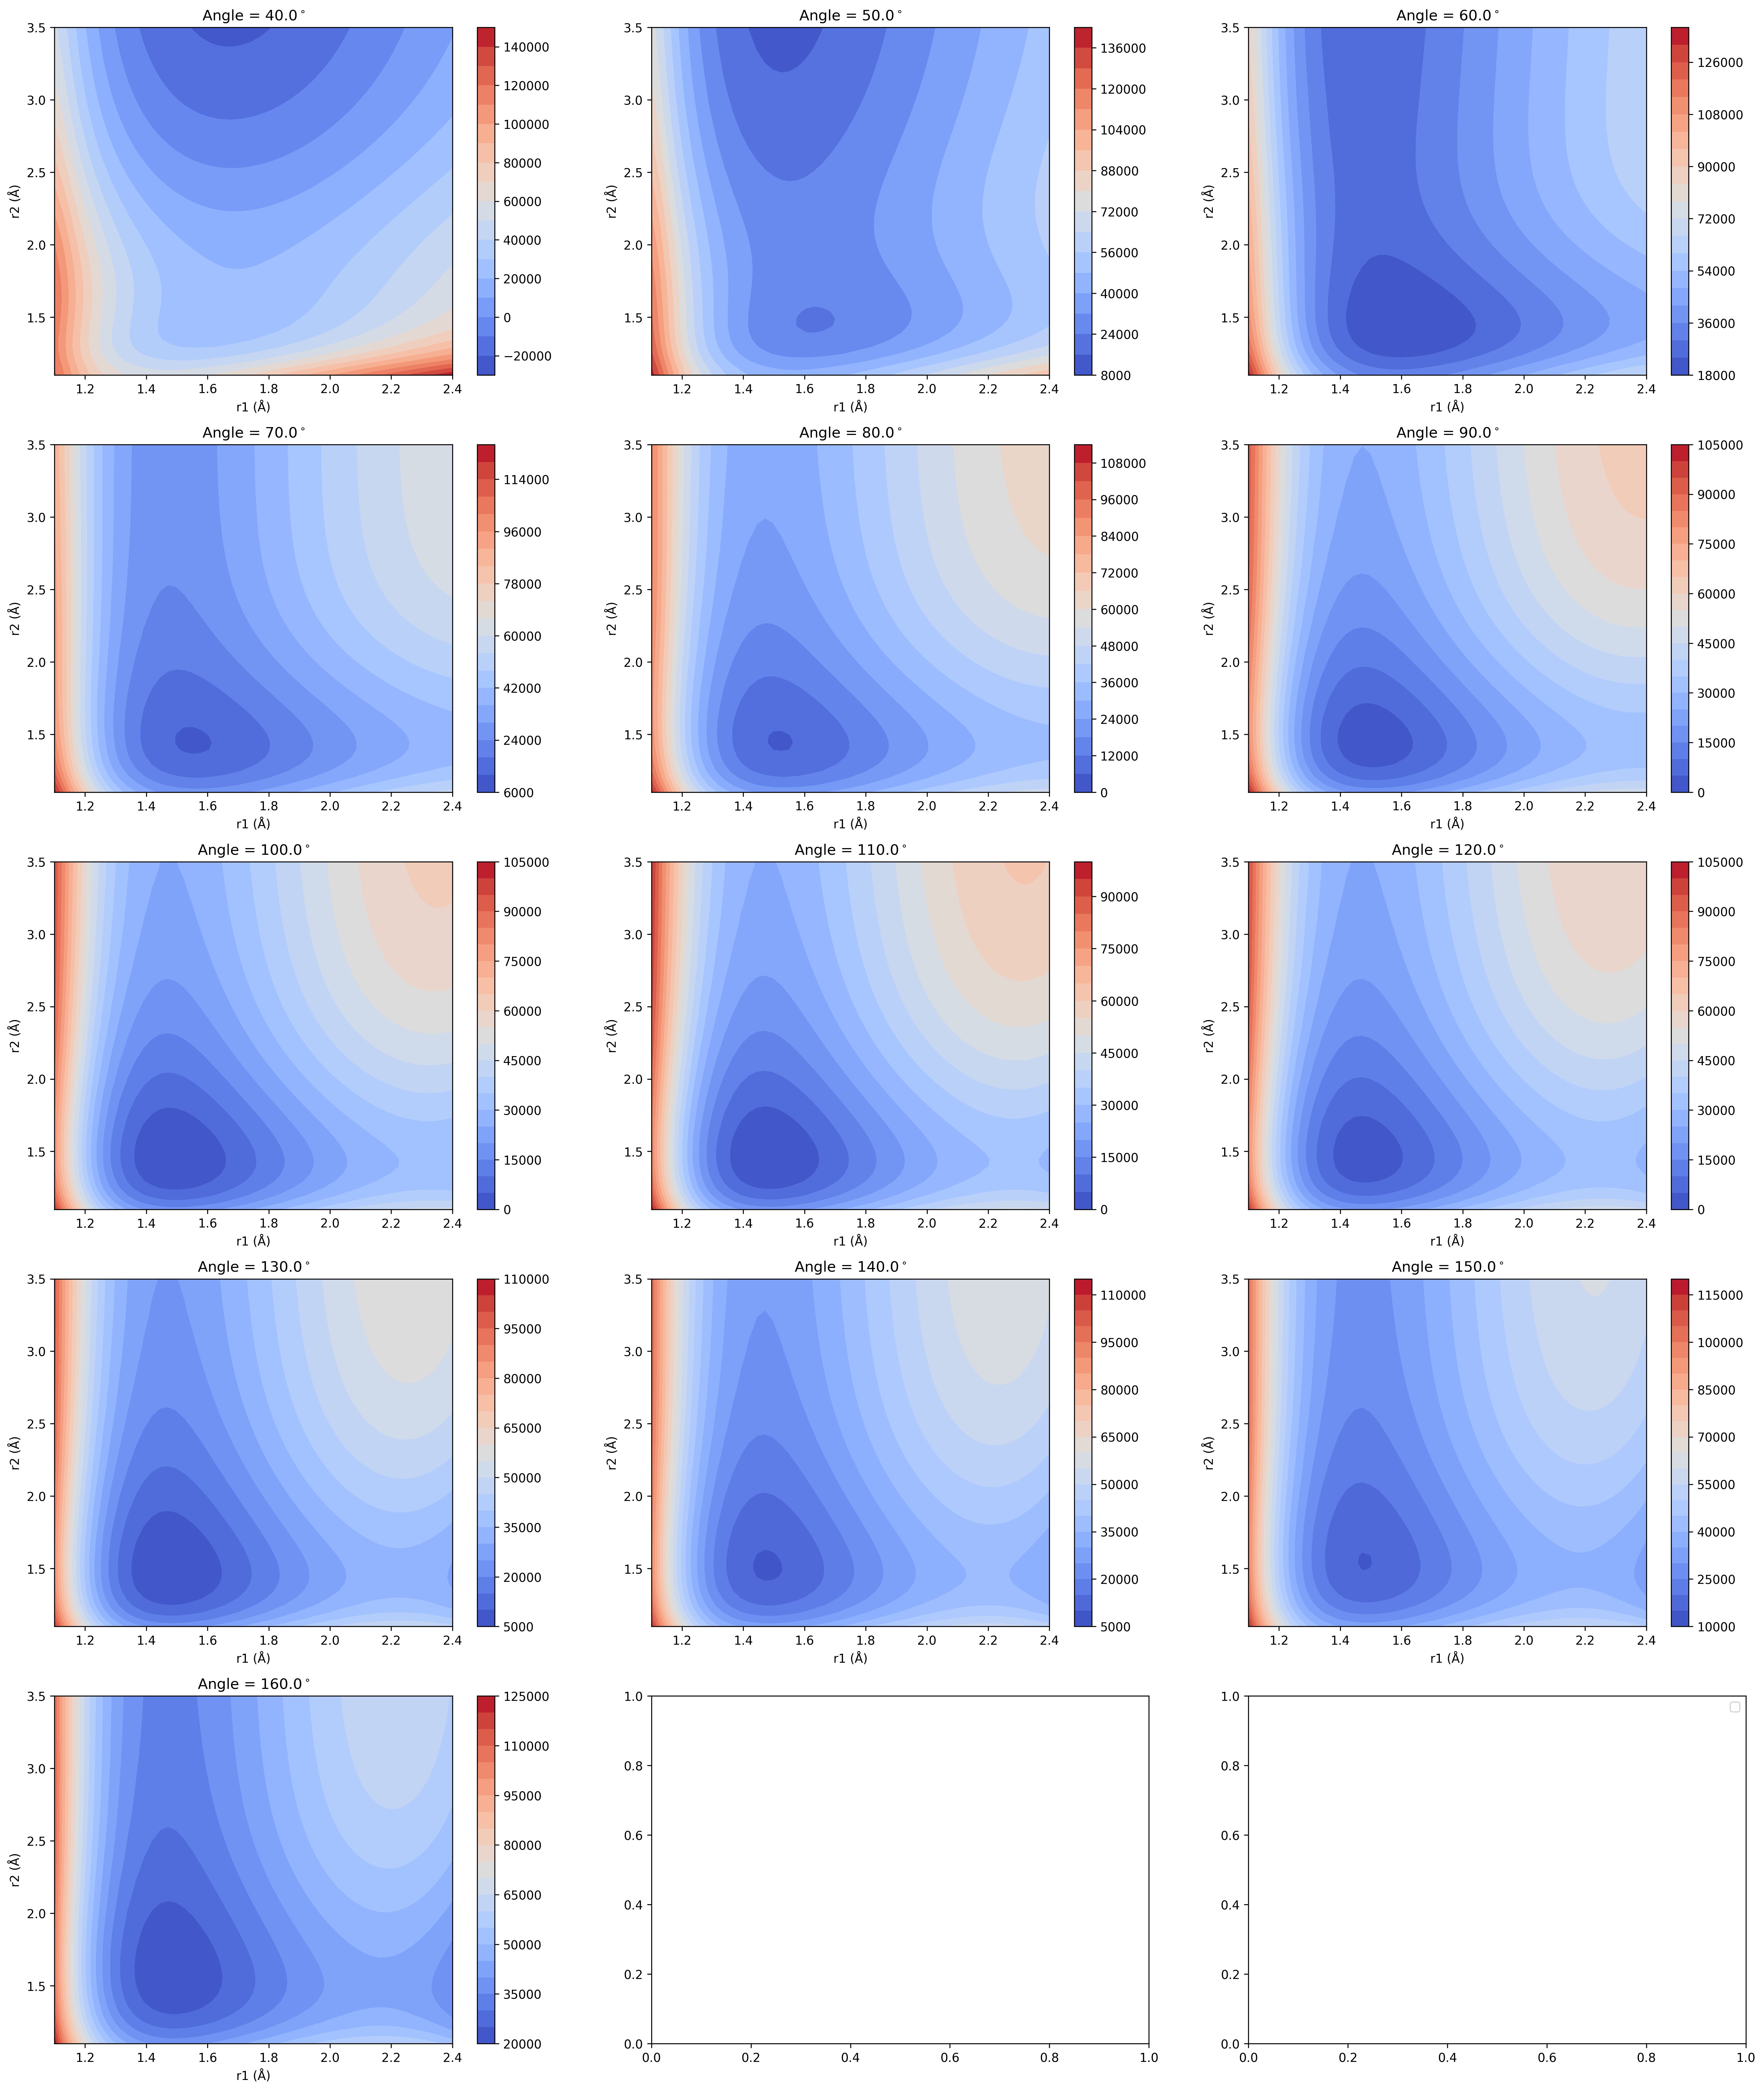

In [26]:
equilibriums = np.array([0.148350247959E+01,
                         0.145448124026E+01,
                         0.104386978891E+03])

r1_grid = np.linspace(1.1,2.4, 50)
r2_grid = np.linspace(1.1,3.5, 50)
a_grid = np.arange(40.0, 165.0, 10)

fig, ax = plt.subplots(5, 3, figsize=(25, 30), dpi=300)
ax = ax.flatten()

for i in range(len(a_grid)):
    angle = a_grid[i]
    r1r2_mesh = np.meshgrid(r1_grid, r2_grid)
    r1_mesh = r1r2_mesh[0]
    r2_mesh = r1r2_mesh[1]

    geometry_r1r2= np.zeros((len(r1_grid)*len(r2_grid), 
                           3) )
    geometry_r1r2[:, 0] = r1_mesh.flatten()
    geometry_r1r2[:, 1] = r2_mesh.flatten()
    geometry_r1r2[:, 2] = angle

    pes_vals = pes(geometry_r1r2)
    pes_vals = np.reshape(pes_vals, 
                        (len(r1_grid), len(r2_grid)) #shape 
                       )
    

    ax[i].set_title(f'Angle = {angle:.1f}$^\\circ$')
    ax[i].set_xlabel('r1 (Å)')
    ax[i].set_ylabel('r2 (Å)')

    contour = ax[i].contourf(
    r1_mesh, r2_mesh, pes_vals,
    levels=20,
    cmap=cm.coolwarm,
    label = f'Angle = {angle}'
    )
    plt.colorbar(contour, ax=ax[i])
    plt.legend()

#geometry1d = np.zeros((100, 3))
#for j in range(3):
#    geometry1d[:, j] = equilibriums[j]
#
#geometry1d[:, 1] = np.linspace(1.0,3.5, 100)
#
#fig, ax = plt.figure()
#plt.plot(geometry1d[:, 1], pes(geometry1d), label='PES')

In [19]:
len(a_grid)

13